Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


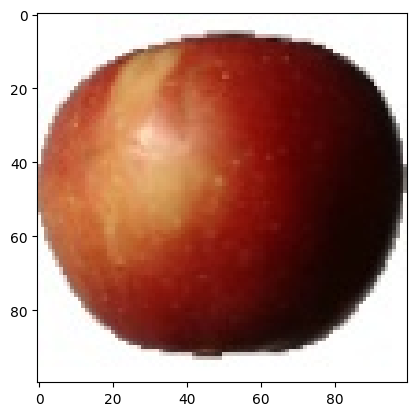

Image Shape: (100, 100, 3)
Found 1100 images belonging to 3 classes.
Found 1100 images belonging to 3 classes.
Number of Classes Detected: 3


/usr/local/lib/python3.10/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 98, 98, 128)         │           3,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 49, 49, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 47, 47, 64)          │          73,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 45, 45, 64)          │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 22, 22, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 30976)               │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 5000)                │     154,885,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 1000)                │       5,001,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 3)                   │           3,003 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 160,003,307 (610.36 MB)

 Trainable params: 160,003,307 (610.36 MB)

 Non-trainable params: 0 (0.00 B)

None
Epoch 1/50
69/69 ━━━━━━━━━━━━━━━━━━━━ 226s 3s/step - accuracy: 0.5445 - loss: 0.9526 - val_accuracy: 0.8445 - val_loss: 0.5274
Epoch 2/50


AttributeError: 'NoneType' object has no attribute 'items'

In [2]:
# Import required libraries
import tensorflow as tf
import os
from tensorflow.keras.preprocessing.image import img_to_array, load_img
import numpy as np
import cv2
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Dropout, Flatten, Dense
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

# Mount Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Define paths to training and test datasets
train_path = '/content/drive/MyDrive/Test Data'  # Make sure this path is correct
test_path = '/content/drive/MyDrive/Test Data'  # Make sure this path is correct

# Set batch size
BatchSize = 16

# Load and display a sample image to verify path
sample_image_path = train_path + '/Apple Braeburn 1/321_100.jpg'  # Adjusted path to image
if not os.path.exists(sample_image_path):
    raise FileNotFoundError(f"Sample image not found at {sample_image_path}. Please check the path and directory structure.")

img = load_img(sample_image_path)  # Load sample image
plt.imshow(img)
plt.show()

# Convert the image to an array and display shape
imgA = img_to_array(img)
print(f"Image Shape: {imgA.shape}")

# Create ImageDataGenerators for training and testing
train_datagen = ImageDataGenerator(
    rescale=1./255,  # Normalize the images
    shear_range=0.3,
    horizontal_flip=True,
    vertical_flip=True,
    zoom_range=0.3
)

test_datagen = ImageDataGenerator(rescale=1./255)  # Normalize test images

# Generate data from the directories and check if the directories exist
if not os.path.exists(train_path):
    raise FileNotFoundError(f"Training path not found at {train_path}. Make sure the directory exists and has subfolders for each class.")

if not os.path.exists(test_path):
    raise FileNotFoundError(f"Test path not found at {test_path}. Make sure the directory exists and has subfolders for each class.")

train_generator = train_datagen.flow_from_directory(
    train_path,
    target_size=(100, 100),
    batch_size=BatchSize,
    color_mode="rgb",
    class_mode="categorical",
    shuffle=True
)

test_generator = test_datagen.flow_from_directory(
    test_path,
    target_size=(100, 100),
    batch_size=BatchSize,
    color_mode="rgb",
    class_mode="categorical"
)

# Check if generators have loaded data correctly
if train_generator.samples == 0:
    raise ValueError(f"No training images found in {train_path}. Please check the directory structure.")
if test_generator.samples == 0:
    raise ValueError(f"No test images found in {test_path}. Please check the directory structure.")

# Calculate the number of classes dynamically
num_classes = train_generator.num_classes
print(f"Number of Classes Detected: {num_classes}")

# Create the Convolutional Neural Network (CNN) model
model = Sequential()
model.add(Conv2D(filters=128, kernel_size=3, activation="relu", input_shape=(100, 100, 3)))
model.add(MaxPooling2D())
model.add(Conv2D(filters=64, kernel_size=3, activation="relu"))
model.add(Conv2D(filters=64, kernel_size=3, activation="relu"))
model.add(MaxPooling2D())
model.add(Flatten())
model.add(Dense(5000, activation="relu"))
model.add(Dense(1000, activation="relu"))
model.add(Dense(num_classes, activation="softmax"))  # Adjusted number of output classes

# Display the model summary
print(model.summary())

# Compile the model
model.compile(loss="categorical_crossentropy", optimizer="SGD", metrics=["accuracy"])

# Calculate steps per epoch and validation steps (Convert to int)
stepsPerEpoch = int(np.ceil(train_generator.samples / BatchSize))
ValidationSteps = int(np.ceil(test_generator.samples / BatchSize))

# Early stopping to avoid overfitting
stop_early = EarlyStopping(monitor="val_accuracy", patience=5)

# Train the model with validation data
history = model.fit(
    train_generator,
    steps_per_epoch=stepsPerEpoch,
    epochs=50,
    validation_data=test_generator,
    validation_steps=ValidationSteps,
    callbacks=[stop_early]
)

# Save the trained model
model.save('fruit_model.h5')
